## 1. Find the dataset folder

Look for a folder containing both the original training and test folders. The dataset can show up under two paths. The next cell uses the first path we verified.

In [1]:
import os

# Find the folders that contain both splits.
for folder, subfolders, _ in os.walk("/kaggle/input"):
    if "train" in subfolders and "test" in subfolders:
        print(folder)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset
/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset/dataset


## 2. Check the four classes

We use four labels: fresh apples, fresh bananas, rotten apples, and rotten bananas. We count the selected images in each original split to verify which files are available.

In [2]:
from torchvision import datasets

data_path = "/kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset"
fruit_classes = ["freshapples", "freshbanana", "rottenapples", "rottenbanana"]

# Count images from the four selected classes in each split.
for split in ["train", "test"]:
    fruit_data = datasets.ImageFolder(os.path.join(data_path, split))
    print(split)

    for fruit_class in fruit_classes:
        class_index = fruit_data.class_to_idx[fruit_class]
        print(fruit_class, fruit_data.targets.count(class_index))

train
freshapples 1693
freshbanana 1581
rottenapples 2342
rottenbanana 2224
test
freshapples 395
freshbanana 381
rottenapples 601
rottenbanana 530


## 3. Prepare the four class folders

Copy the selected folders to a temporary location so ImageFolder can read the four labels directly. Each image stays in its original training or test split.

In [3]:
from shutil import copytree

selected_path = "/tmp/selected_fruits"

# Copy the selected classes within each original split.
for split in ["train", "test"]:
    for fruit_class in fruit_classes:
        source = os.path.join(data_path, split, fruit_class)
        destination = os.path.join(selected_path, split, fruit_class)
        copytree(source, destination, dirs_exist_ok=True)

print("Four class folders are ready.")

Four class folders are ready.


## 4. Load and resize the images

Resize images to 32 × 32 to match the faculty example and keep the input small. Random horizontal flips add variety during training while preserving the fruit label. Validation and test images are resized and converted to tensors.

In [4]:
import torchvision.transforms as transforms

size = 32

# Apply the random flip during training.
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

# Use fixed preprocessing for validation and testing.
val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

train_folder = os.path.join(selected_path, "train")
test_folder = os.path.join(selected_path, "test")

train_images = datasets.ImageFolder(train_folder, transform=train_transform)
val_images = datasets.ImageFolder(train_folder, transform=val_transform)
test_data = datasets.ImageFolder(test_folder, transform=val_transform)

print(train_images.class_to_idx)
print("Original training images:", len(train_images))
print("Test images:", len(test_data))

{'freshapples': 0, 'freshbanana': 1, 'rottenapples': 2, 'rottenbanana': 3}
Original training images: 7840
Test images: 1907


## 5. Split training and validation

Hold out 10% of the original training images for validation. A fixed seed makes this split repeatable. The split gives 7,056 training images and 784 validation images, with 1,907 images in the original test set.

In [5]:
import torch
from torch.utils.data import random_split, Subset

val_size = len(train_images) // 10
train_size = len(train_images) - val_size

train_data, val_split = random_split(
    train_images,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Use the selected validation images with the fixed preprocessing.
val_data = Subset(val_images, val_split.indices)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

Training images: 7056
Validation images: 784
Test images: 1907


## 6. Create the data loaders

The loaders feed up to 32 images at a time. This batch size matches the example and keeps each batch small enough to process on the GPU. We shuffle training images and check that a full batch contains 32 RGB images.

In [6]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

# Check the dimensions of one training batch.
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([32, 3, 32, 32])
Label batch shape: torch.Size([32])


## 7. Show sample fruit images

Display the first image from each class at its original resolution so the labels and appearance are easy to check.

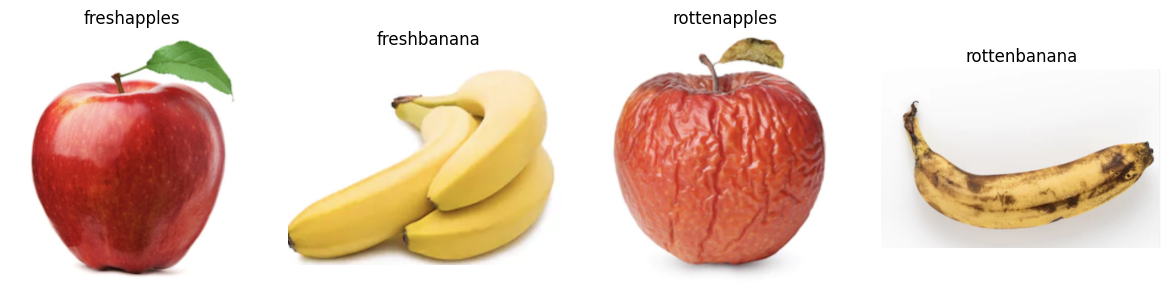

In [7]:
import matplotlib.pyplot as plt

sample_data = datasets.ImageFolder(train_folder)
class_names = sample_data.classes

plt.figure(figsize=(12, 3))

for i in range(len(class_names)):
    # Find the first image with this class number.
    index = sample_data.targets.index(i)
    image, label = sample_data[index]

    plt.subplot(1, 4, i + 1)
    plt.imshow(image)
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 8. Build the CNN

Two convolution blocks learn visual features. ReLU helps the model learn more varied patterns, and max pooling reduces the size of the feature maps. The final layer produces one score for each of the four classes. Adam at 0.001 matches the starting setting in the example and adjusts the weight updates during training. Cross-entropy measures how well the scores match the single correct class.

In [8]:
import torch.nn as nn
from torch.optim import Adam

device = "cuda" if torch.cuda.is_available() else "cpu"
learning_rate = 0.001

def get_model():
    return nn.Sequential(
        # Learn features with two convolution blocks.
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        # Turn the feature maps into a vector for classification.
        nn.Flatten(),
        nn.Linear(128 * 6 * 6, 256),
        nn.ReLU(),
        nn.Linear(256, 4)
    )

model = get_model().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=learning_rate)

print("Device:", device)
print(model)

Device: cuda
Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4608, out_features=256, bias=True)
  (8): ReLU()
  (9): Linear(in_features=256, out_features=4, bias=True)
)


## 9. Show the model summary

Check the shape and parameter count of each layer. The input is a 3-channel, 32 × 32 image. The final layer has four outputs, and the model has 1,256,580 trainable parameters.

In [9]:
from torchsummary import summary

# Show the layer shapes and parameter counts for an RGB image.
summary(model, input_size=(3, size, size))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 4]           1,028
Total params: 1,256,580
Trainable params: 1,256,580
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.79
Estimat

## 10. Define one training epoch

Pass each batch through the model, calculate the loss, and update the weights. The returned loss and accuracy are averages over all training images.

In [10]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    total_loss = 0
    correct = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear the previous gradients before processing this batch.
        optimizer.zero_grad()
        predictions = model(images)
        loss = loss_fn(predictions, labels)
        loss.backward()
        optimizer.step()

        # Count each image equally when averaging the loss.
        total_loss += loss.item() * len(labels)
        correct += (predictions.argmax(1) == labels).sum().item()

    total_images = len(data_loader.dataset)
    return total_loss / total_images, correct / total_images

## 11. Train and validate the CNN

Train for 10 epochs as in the faculty example to see how performance changes over repeated passes through the data. Check validation loss and accuracy after each epoch and save the weights with the lowest validation loss.

In [11]:
# Evaluate using the current model weights.
@torch.no_grad()
def evaluate(data_loader, model, loss_fn):
    model.eval()
    total_loss = 0
    correct = 0

    for images, labels in data_loader:
        images, labels = images.to(device), labels.to(device)
        predictions = model(images)
        loss = loss_fn(predictions, labels)

        total_loss += loss.item() * len(labels)
        correct += (predictions.argmax(1) == labels).sum().item()

    total_images = len(data_loader.dataset)
    return total_loss / total_images, correct / total_images


epochs = 10
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
best_val_loss = float("inf")
model_path = "/kaggle/working/fruit_cnn.pth"

for epoch in range(1, epochs + 1):
    train_loss, train_acc = train_one_epoch(train_loader, model, loss_fn, optimizer)
    val_loss, val_acc = evaluate(val_loader, model, loss_fn)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    # Save the weights when validation loss improves.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), model_path)

    print(
        f"Epoch {epoch}/{epochs} | "
        f"Train loss: {train_loss:.4f}, accuracy: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f}, accuracy: {val_acc:.2%}"
    )

Epoch 1/10 | Train loss: 0.4154, accuracy: 83.72% | Val loss: 0.4729, accuracy: 84.44%
Epoch 2/10 | Train loss: 0.1714, accuracy: 93.62% | Val loss: 0.1866, accuracy: 93.88%
Epoch 3/10 | Train loss: 0.1296, accuracy: 94.93% | Val loss: 0.1275, accuracy: 94.77%
Epoch 4/10 | Train loss: 0.1176, accuracy: 95.55% | Val loss: 0.1424, accuracy: 94.01%
Epoch 5/10 | Train loss: 0.0891, accuracy: 96.57% | Val loss: 0.1584, accuracy: 94.52%
Epoch 6/10 | Train loss: 0.0730, accuracy: 97.26% | Val loss: 0.0527, accuracy: 98.21%
Epoch 7/10 | Train loss: 0.0614, accuracy: 97.73% | Val loss: 0.0680, accuracy: 97.19%
Epoch 8/10 | Train loss: 0.0526, accuracy: 98.21% | Val loss: 0.0483, accuracy: 98.34%
Epoch 9/10 | Train loss: 0.0422, accuracy: 98.27% | Val loss: 0.0406, accuracy: 97.96%
Epoch 10/10 | Train loss: 0.0361, accuracy: 98.70% | Val loss: 0.0262, accuracy: 99.11%


## 12. Plot loss and accuracy

Compare the training and validation curves across the 10 epochs. Lower loss and higher accuracy show improvement. The accuracy axis uses fractions, so 0.98 means 98%.

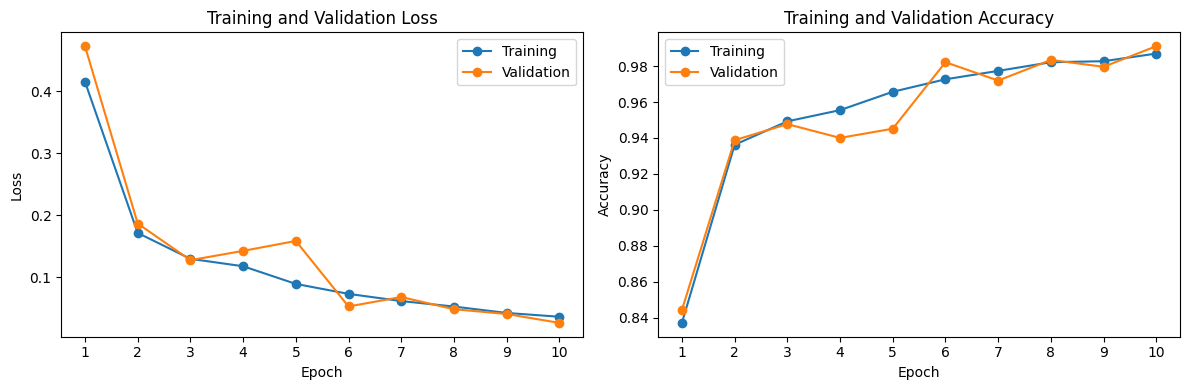

In [12]:
epoch_numbers = range(1, epochs + 1)

plt.figure(figsize=(12, 4))

# Draw the loss curve on the left.
plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, train_losses, marker="o", label="Training")
plt.plot(epoch_numbers, val_losses, marker="o", label="Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epoch_numbers)
plt.legend()

# Draw the accuracy curve on the right.
plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, train_accuracies, marker="o", label="Training")
plt.plot(epoch_numbers, val_accuracies, marker="o", label="Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epoch_numbers)
plt.legend()

plt.tight_layout()
plt.show()

## 13. Reload the model and test it

Create the same CNN, load the saved weights, and report loss and accuracy on the held-out test set.

In [13]:
saved_model = get_model().to(device)
saved_model.load_state_dict(torch.load(model_path, map_location=device))

# Measure final performance on the test images.
test_loss, test_accuracy = evaluate(test_loader, saved_model, loss_fn)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.0246
Test accuracy: 99.32%


## 14. Show actual and predicted labels

Show one test example per class. The plot uses the original image for clarity, and the model uses the resized version of that same image.

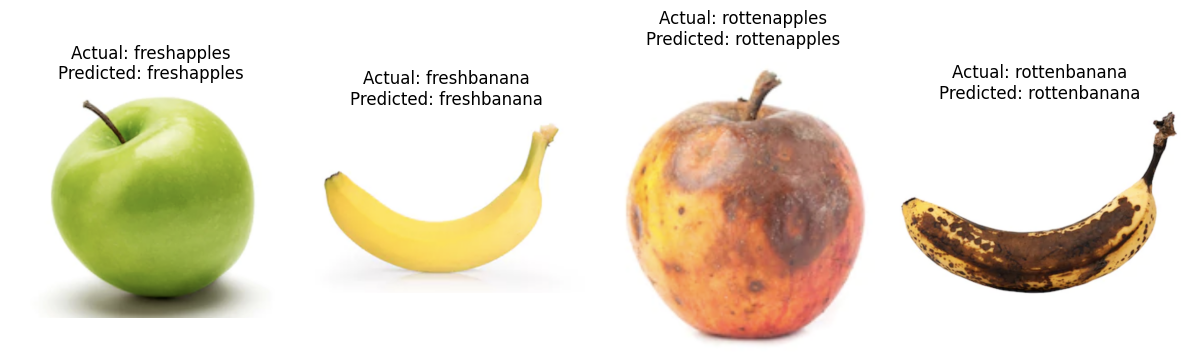

In [14]:
test_samples = datasets.ImageFolder(test_folder)

plt.figure(figsize=(12, 4))

with torch.no_grad():
    for i in range(len(class_names)):
        index = test_samples.targets.index(i)
        original_image, label = test_samples[index]
        image, _ = test_data[index]

        output = saved_model(image.view(1, 3, size, size).to(device))
        # Use the class with the highest score as the prediction.
        prediction = output.argmax(1).item()

        plt.subplot(1, 4, i + 1)
        plt.imshow(original_image)
        plt.title(f"Actual: {class_names[label]}\nPredicted: {class_names[prediction]}")
        plt.axis("off")

plt.tight_layout()
plt.show()